# 03 · Zero-DCE: low-light brightening

**What it is.** Zero-DCE (Zero-Reference Deep Curve Estimation, Guo et al., CVPR 2020) predicts per-pixel brightness curves from a single dark photograph. FaceCloud runs the official *Epoch99* weights exported to ONNX (`zero_dce_epoch99.onnx`, 313 KB).

**What was done with it here.** It was *selected and integrated*. This notebook measures what it does on the project's own dark photographs and compares it with a plain gamma curve (the classical baseline), then reads from the database how often the pipeline actually used it and how often its judge accepted the result.

**Honest limit.** A dark photograph has no ground-truth bright version, so there is no PSNR here. The scores are brightness gained, noise amplification and shadow clipping, plus the pipeline's own accept/reject decision.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from common import *
print("project root:", ROOT)

project root: /Users/Ali/Projects/FaceCloud_backend


## 1 · Run Zero-DCE and the gamma baseline on the dark public-stock photographs

In [2]:
from enhancement.zero_dce import enhance_with_zero_dce

def gamma(image, g=0.55):
    table = (np.linspace(0, 1, 256) ** g * 255).astype(np.uint8)
    return cv2.LUT(image, table)

dark = [pk for pk in public_stock_ids() if brightness(photo(pk, 500)) < 85][:8]
rows, shown = [], []
for pk in dark:
    source = photo(pk, 700)
    out, seconds = timed(lambda: first(enhance_with_zero_dce(source)))
    base = gamma(source)
    rows.append({"photo": pk, "bright_in": round(brightness(source), 1), "bright_zdce": round(brightness(out), 1), "bright_gamma": round(brightness(base), 1),
                 "noise_in": round(noise_sigma(source), 2), "noise_zdce": round(noise_sigma(out), 2), "noise_gamma": round(noise_sigma(base), 2),
                 "ssim_zdce": round(ssim(source, out), 3), "seconds": round(seconds, 2)})
    shown.append((source, out, base))
table(rows)

photo  bright_in  bright_zdce  bright_gamma  noise_in  noise_zdce  noise_gamma  ssim_zdce  seconds
-----  ---------  -----------  ------------  --------  ----------  -----------  ---------  -------
75     50.2       125.3        98.9          14.83     29.65       17.79        0.542      0.26   
76     20.7       94.6         58.8          1.48      7.41        2.97         0.331      0.18   
78     72.1       132.0        117.9         2.97      4.45        2.97         0.653      0.19   
79     69.3       143.4        120.5         2.97      4.45        2.97         0.706      0.24   
81     62.1       134.0        108.4         1.48      2.97        2.97         0.605      0.18   
82     55.2       134.5        100.5         2.97      5.93        2.97         0.549      0.17   
83     21.2       103.4        62.7          1.48      5.93        2.97         0.359      0.19   
84     34.2       120.8        80.6          1.48      4.45        1.48         0.454      0.18   


## 2 · Scores

mean brightness gain  Zero-DCE: x3.00   gamma: x2.13


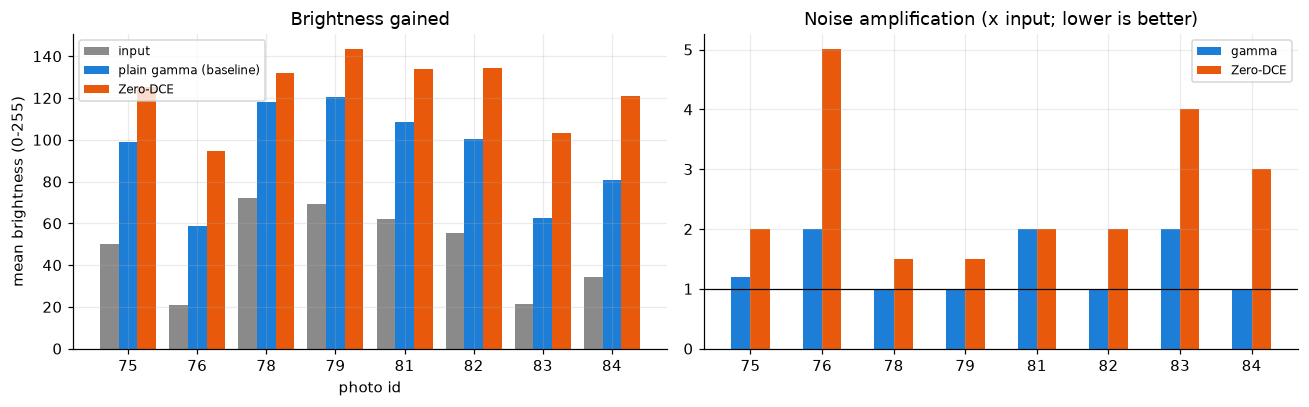

In [3]:
x = np.arange(len(rows)); w = 0.27
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(x - w, [r["bright_in"] for r in rows], w, label="input", color=COLORS["input"])
ax[0].bar(x, [r["bright_gamma"] for r in rows], w, label="plain gamma (baseline)", color=COLORS["baseline"])
ax[0].bar(x + w, [r["bright_zdce"] for r in rows], w, label="Zero-DCE", color=COLORS["model"])
ax[0].set_xticks(x, [r["photo"] for r in rows]); ax[0].set_xlabel("photo id"); ax[0].set_ylabel("mean brightness (0-255)"); ax[0].set_title("Brightness gained"); ax[0].legend(fontsize=8)
ax[1].bar(x - w / 2, [r["noise_gamma"] / max(r["noise_in"], 0.1) for r in rows], w, label="gamma", color=COLORS["baseline"])
ax[1].bar(x + w / 2, [r["noise_zdce"] / max(r["noise_in"], 0.1) for r in rows], w, label="Zero-DCE", color=COLORS["model"])
ax[1].axhline(1, color="k", lw=0.8); ax[1].set_xticks(x, [r["photo"] for r in rows]); ax[1].set_title("Noise amplification (x input; lower is better)"); ax[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "03_zero_dce_scores.png")
print("mean brightness gain  Zero-DCE: x%.2f   gamma: x%.2f" % (np.mean([r["bright_zdce"] / r["bright_in"] for r in rows]), np.mean([r["bright_gamma"] / r["bright_in"] for r in rows])))

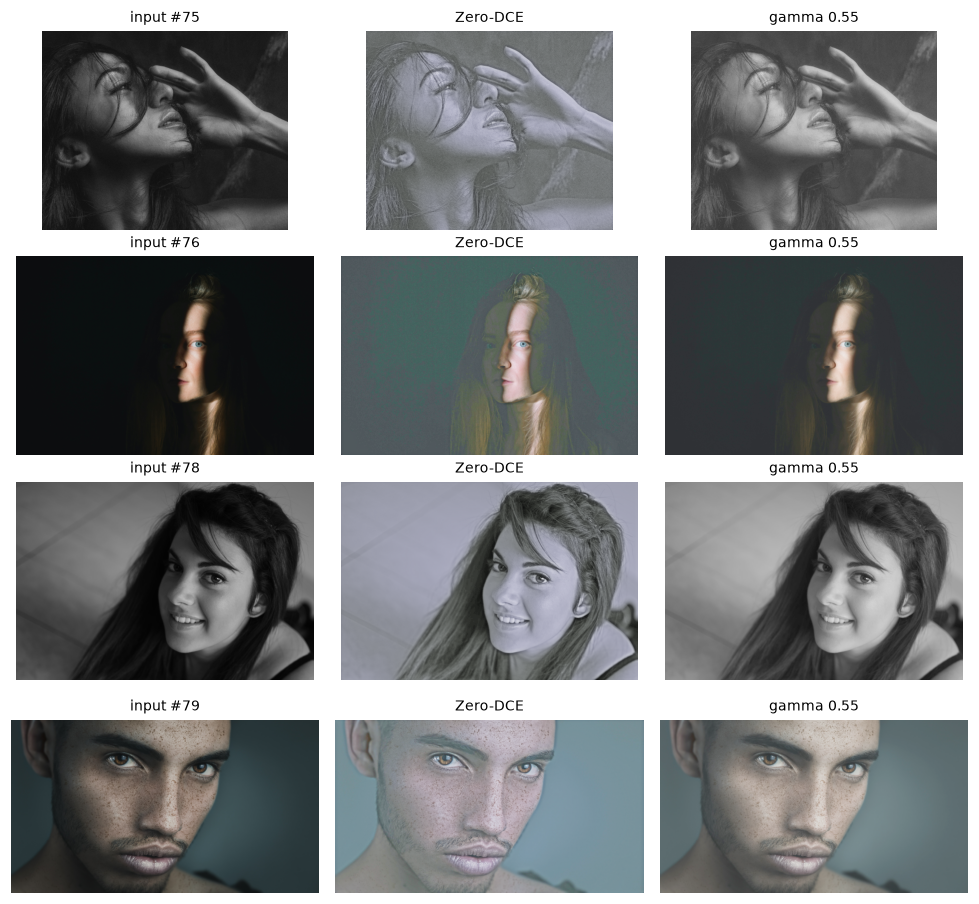

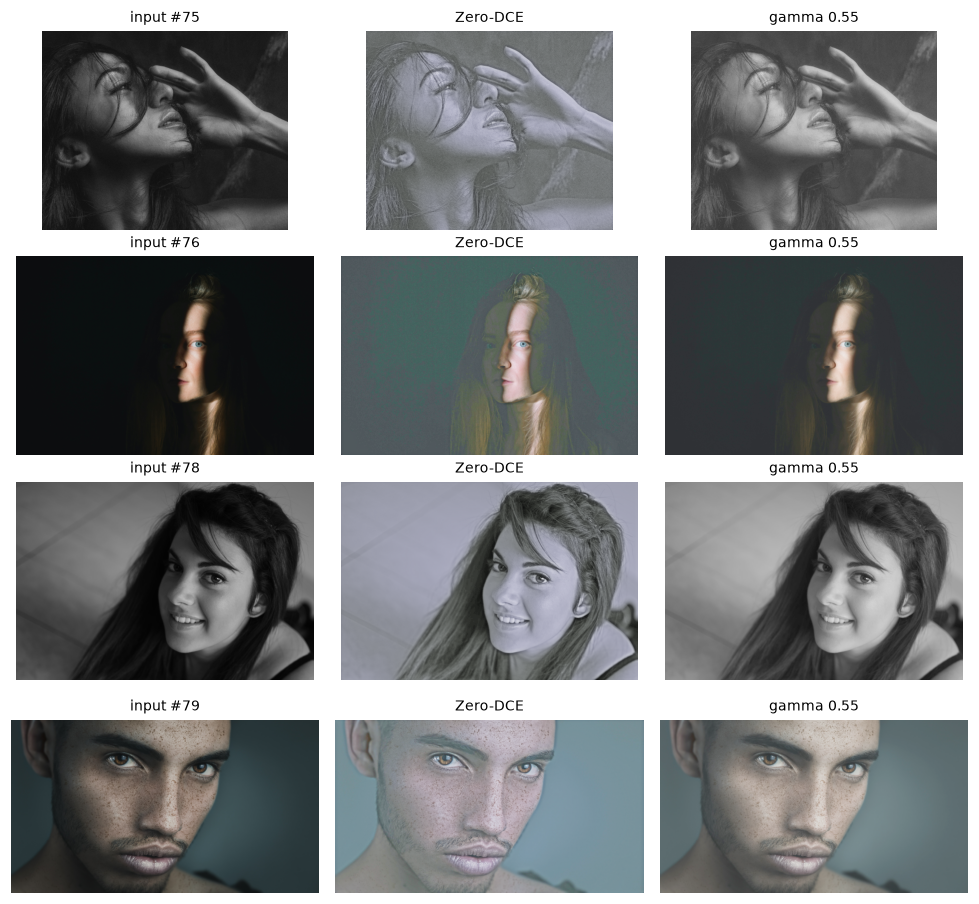

In [4]:
pick = shown[:4]
images = [im for trio in pick for im in trio]
titles = [t for i in range(len(pick)) for t in (f"input #{dark[i]}", "Zero-DCE", "gamma 0.55")]
fig = montage(images, titles, columns=3, width=3.0); fig.set_size_inches(9, 2.1 * len(pick)); save(fig, "03_zero_dce_examples.png")

## 3 · Is the model really used by the application? (read from the database)

In [5]:
from collections import Counter
from enhancement.models import ImageEnhancementResult
run, accepted = Counter(), Counter()
for result in ImageEnhancementResult.objects.filter(status="completed"):
    for stage in (result.applied_parameters.get("adaptive") or {}).get("stages") or []:
        for engine in stage.get("models_run") or []:
            run[(stage["operation"], engine)] += 1
            if stage.get("status") == "accepted" and stage.get("chosen", "").split("_", 1)[-1] == stage["operation"]:
                accepted[(stage["operation"], engine)] += 1
for key in [("low_light_enhancement", "zero_dce"), ("low_light_enhancement", "opencv_exposure")]:
    print(f"{key[1]:18s} ran in {run[key]:3d} results of the low-light stage")
print("The router tries Zero-DCE first for dark scenes; the validator (SSIM, identity, clipping gates) then accepts or rejects it, and a plain exposure curve is the fallback.")
save_json("03_zero_dce.json", {"rows": rows, "used_in_pipeline": {f"{a}/{b}": n for (a, b), n in run.items() if b in ("zero_dce", "opencv_exposure")}})

zero_dce           ran in  75 results of the low-light stage
opencv_exposure    ran in  26 results of the low-light stage
The router tries Zero-DCE first for dark scenes; the validator (SSIM, identity, clipping gates) then accepts or rejects it, and a plain exposure curve is the fallback.


## Scorecard (evaluation metrics)

In [6]:
# Scorecard: the headline numbers of this model (no ground truth exists for a dark photo, so PSNR is not applicable)
metrics = {"images": len(rows), "mean_brightness_gain_x": float(np.mean([r["bright_zdce"] / r["bright_in"] for r in rows])),
           "gamma_baseline_gain_x": float(np.mean([r["bright_gamma"] / r["bright_in"] for r in rows])),
           "noise_amplification_x": float(np.mean([r["noise_zdce"] / max(r["noise_in"], 0.1) for r in rows])),
           "mean_ssim_vs_input": float(np.mean([r["ssim_zdce"] for r in rows])), "mean_seconds": float(np.mean([r["seconds"] for r in rows]))}
print(scorecard("Zero-DCE", "low-light enhancement", metrics, "no ground truth: brightness gain, noise amplification, SSIM to input"))

{'task': 'low-light enhancement', 'metrics': {'images': 8, 'mean_brightness_gain_x': 2.9963, 'gamma_baseline_gain_x': 2.1332, 'noise_amplification_x': 2.6275, 'mean_ssim_vs_input': 0.5249, 'mean_seconds': 0.1987}, 'note': 'no ground truth: brightness gain, noise amplification, SSIM to input'}


## 4 · Verdict
* Zero-DCE lifts dark photographs more strongly than a fixed gamma curve (about 3x against 2.1x mean brightness, see the scorecard) in well under a second (ONNX, Apple GPU).
* It also amplifies noise in dark areas, which is why the pipeline judges every result (noise, clipping and identity gates) before accepting it, and why a denoise step can follow.
* The official public weights are used. The *project's own work* is the router, the gates and the thresholds around it.